In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

from google.colab import files

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    VotingRegressor,
    StackingRegressor,
    IsolationForest
)
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.multioutput import MultiOutputRegressor
from sklearn.inspection import permutation_importance

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

print("All libraries imported successfully.")

All libraries imported successfully.


In [ ]:
uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Saving Solar_Cell_data_set_2.csv to Solar_Cell_data_set_2 (1).csv
Dataset loaded successfully!
Dataset shape: (20000, 30)


,Cell_stack_sequence,Cell_architecture,Substrate_stack_sequence,ETL_stack_sequence,ETL_deposition_procedure,Perovskite_composition_a_ions,Perovskite_composition_b_ions,Perovskite_composition_c_ions,Perovskite_composition_short_form,Perovskite_additives_compounds,...,Backcontact_stack_sequence,Backcontact_thickness_list,Backcontact_deposition_procedure,Encapsulation,Encapsulation_stack_sequence,JV_measured,JV_default_Voc,JV_default_Jsc,JV_default_FF,JV_default_PCE
0,SLG | FTO | TiO2-c | TiO2-mp | Perovskite | Ca...,nip,SLG | FTO,TiO2-c | TiO2-mp,Spin-coating | Spin-coating,Cs,Pb,Br; I,CsPbBrI,Undoped,...,Carbon,NaN,Doctor blading,False,Unknown,True,1.096,16.32,0.63,11.30
1,SLG | ITO | SnO2-np | Perovskite | Spiro-MeOTA...,nip,SLG | ITO,SnO2-np,Spin-coating,FA; MA,Pb,Br; I,FAMAPbBrI,Rb,...,Au,100.0,Evaporation,False,Unknown,True,1.138,21.14,0.63,15.08
2,SLG | ITO | C60 | BCP | Perovskite | NiO-c | Ag,pin,SLG | ITO,C60 | BCP,Evaporation | Evaporation,Cs; FA; MA,Pb,Br; I,CsFAMAPbBrI,Cl,...,Ag,100.0,Evaporation,False,Unknown,True,1.188,20.98,0.72,18.04
3,SLG | ITO | C60 | BCP | Perovskite | PTAA | Cu,pin,SLG | ITO,C60 | BCP,Evaporation | Evaporation,FA; MA,Pb,Br; I,FAMAPbBrI,5-AVAI,...,Cu,100.0,Evaporation,False,Unknown,True,1.225,20.96,0.77,19.69
4,SLG | FTO | TiO2-c | Perovskite | Spiro-MeOTAD...,nip,SLG | FTO,TiO2-c,Spray-pyrolys,MA,Pb,I,MAPbI,Cl,...,Au,80.0,Evaporation,False,Unknown,True,0.993,19.48,0.70,13.46


In [ ]:
print("Rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

print("\nUnique values per column:")
display(df.nunique().sort_values(ascending=False))

Rows and columns: (20000, 30)

Column names:
['Cell_stack_sequence', 'Cell_architecture', 'Substrate_stack_sequence', 'ETL_stack_sequence', 'ETL_deposition_procedure', 'Perovskite_composition_a_ions', 'Perovskite_composition_b_ions', 'Perovskite_composition_c_ions', 'Perovskite_composition_short_form', 'Perovskite_additives_compounds', 'Perovskite_additives_concentrations', 'Perovskite_thickness', 'Perovskite_deposition_number_of_deposition_steps', 'Perovskite_deposition_procedure', 'Perovskite_deposition_solvents', 'Perovskite_deposition_quenching_induced_crystallisation', 'Perovskite_deposition_thermal_annealing_temperature', 'Perovskite_deposition_thermal_annealing_time', 'HTL_stack_sequence', 'HTL_deposition_procedure', 'Backcontact_stack_sequence', 'Backcontact_thickness_list', 'Backcontact_deposition_procedure', 'Encapsulation', 'Encapsulation_stack_sequence', 'JV_measured', 'JV_default_Voc', 'JV_default_Jsc', 'JV_default_FF', 'JV_default_PCE']

Data types:
<class 'pandas.core.fr

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Cell_stack_sequence,20000,13,SLG | FTO | TiO2-c | TiO2-mp | Perovskite | Sp...,5462,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Cell_architecture,20000,2,nip,13206,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Substrate_stack_sequence,20000,4,SLG | FTO,11027,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ETL_stack_sequence,20000,7,TiO2-c | TiO2-mp,6919,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ETL_deposition_procedure,20000,6,Spray-pyrolys | Spin-coating,5462,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Perovskite_composition_a_ions,20000,6,MA,9926,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Perovskite_composition_b_ions,20000,3,Pb,19156,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Perovskite_composition_c_ions,20000,2,I,11017,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Perovskite_composition_short_form,20000,10,MAPbI,8809,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Perovskite_additives_compounds,20000,8,Cl,6662,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Unique values per column:


,0
JV_default_PCE,1785
JV_default_Jsc,1364
JV_default_Voc,733
JV_default_FF,35
Cell_stack_sequence,13
Perovskite_composition_short_form,10
Perovskite_additives_compounds,8
Perovskite_thickness,8
Perovskite_deposition_thermal_annealing_time,8
HTL_stack_sequence,7


Duplicate rows: 0

Missing values:


,0
Perovskite_thickness,8028
Backcontact_thickness_list,748
JV_default_Jsc,611
JV_default_FF,607
JV_default_Voc,594
JV_default_PCE,412
Perovskite_composition_a_ions,0
Perovskite_composition_b_ions,0
Perovskite_composition_short_form,0
Cell_stack_sequence,0


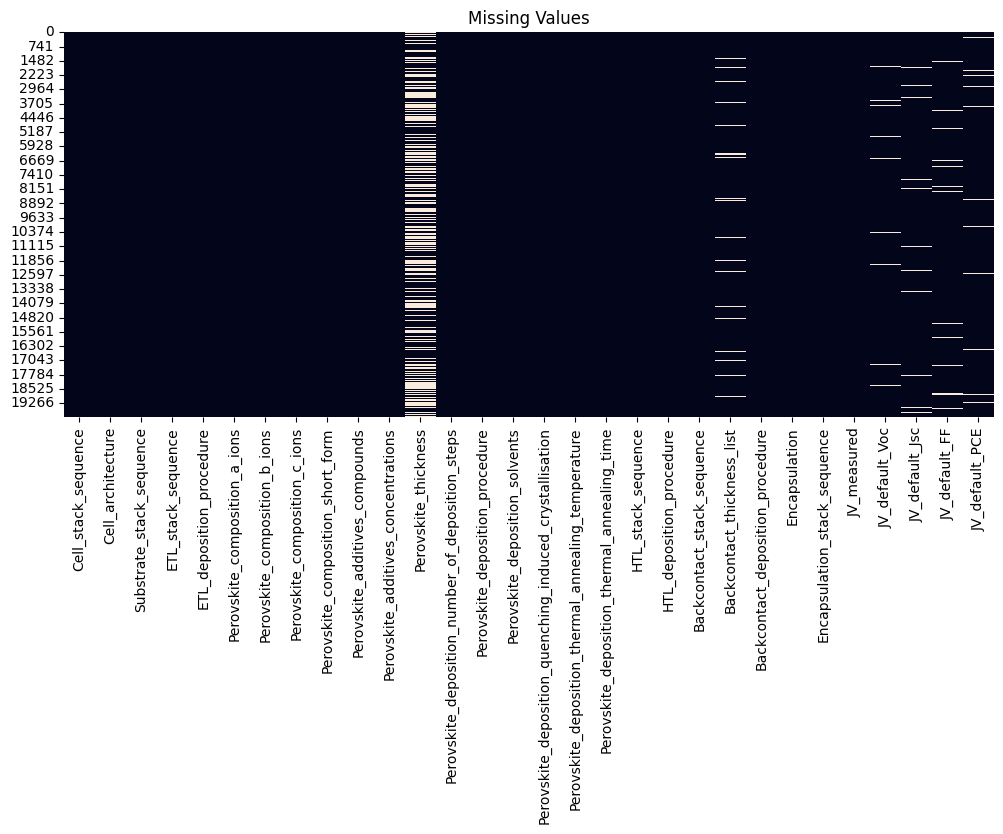

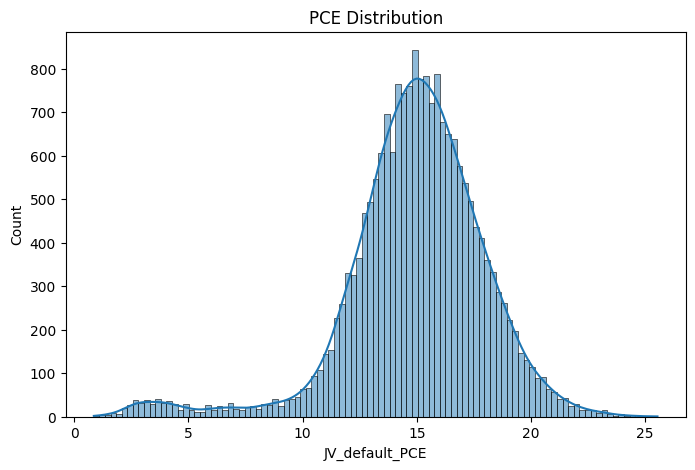

Shape after target cleaning: (19588, 30)


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False))

plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Values")
plt.show()

target = "JV_default_PCE"

if target not in df.columns:
    raise ValueError(f"Target column '{target}' not found.")

df[target] = pd.to_numeric(df[target], errors="coerce")
df = df.dropna(subset=[target]).copy()

# Keep physically plausible PCE values
df = df[df[target].between(0, 100)].copy()

plt.figure(figsize=(8, 5))
sns.histplot(df[target], kde=True)
plt.title("PCE Distribution")
plt.xlabel("JV_default_PCE")
plt.show()

print("Shape after target cleaning:", df.shape)

In [ ]:
target = "JV_default_PCE"

performance_columns = [
    "JV_default_PCE",
    "JV_default_Voc",
    "JV_default_Jsc",
    "JV_default_FF",
    "JV_measured"
]

performance_columns = [
    col for col in performance_columns
    if col in df.columns
]

X = df.drop(columns=performance_columns).copy()
y = df[target].copy()

# Remove columns that contain no information
constant_columns = [
    col for col in X.columns
    if X[col].nunique(dropna=False) <= 1
]

X.drop(columns=constant_columns, inplace=True)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("\nInput features:")
print(X.columns.tolist())
print("\nExcluded performance columns:", performance_columns)
print("Removed constant columns:", constant_columns)

Feature shape: (19588, 25)
Target shape: (19588,)

Input features:
['Cell_stack_sequence', 'Cell_architecture', 'Substrate_stack_sequence', 'ETL_stack_sequence', 'ETL_deposition_procedure', 'Perovskite_composition_a_ions', 'Perovskite_composition_b_ions', 'Perovskite_composition_c_ions', 'Perovskite_composition_short_form', 'Perovskite_additives_compounds', 'Perovskite_additives_concentrations', 'Perovskite_thickness', 'Perovskite_deposition_number_of_deposition_steps', 'Perovskite_deposition_procedure', 'Perovskite_deposition_solvents', 'Perovskite_deposition_quenching_induced_crystallisation', 'Perovskite_deposition_thermal_annealing_temperature', 'Perovskite_deposition_thermal_annealing_time', 'HTL_stack_sequence', 'HTL_deposition_procedure', 'Backcontact_stack_sequence', 'Backcontact_thickness_list', 'Backcontact_deposition_procedure', 'Encapsulation', 'Encapsulation_stack_sequence']

Excluded performance columns: ['JV_default_PCE', 'JV_default_Voc', 'JV_default_Jsc', 'JV_default_F

In [ ]:
for col in X.columns:
    if X[col].dtype == "bool":
        X[col] = X[col].astype(int)

sequence_columns = [
    col for col in X.columns
    if any(word in col.lower() for word in [
        "stack_sequence", "additive"
    ])
]

for col in sequence_columns:
    X[col + "_count"] = X[col].apply(
        lambda value: (
            np.nan if pd.isna(value)
            else len([
                item for item in str(value)
                .replace(";", ",").split(",")
                if item.strip()
            ])
        )
    )

print("Feature engineering completed.")
print("Number of features:", X.shape[1])
display(X.head())

Feature engineering completed.
Number of features: 33


,Cell_stack_sequence,Cell_architecture,Substrate_stack_sequence,ETL_stack_sequence,ETL_deposition_procedure,Perovskite_composition_a_ions,Perovskite_composition_b_ions,Perovskite_composition_c_ions,Perovskite_composition_short_form,Perovskite_additives_compounds,...,Encapsulation,Encapsulation_stack_sequence,Cell_stack_sequence_count,Substrate_stack_sequence_count,ETL_stack_sequence_count,Perovskite_additives_compounds_count,Perovskite_additives_concentrations_count,HTL_stack_sequence_count,Backcontact_stack_sequence_count,Encapsulation_stack_sequence_count
0,SLG | FTO | TiO2-c | TiO2-mp | Perovskite | Ca...,nip,SLG | FTO,TiO2-c | TiO2-mp,Spin-coating | Spin-coating,Cs,Pb,Br; I,CsPbBrI,Undoped,...,0,Unknown,1,1,1,1,1,1,1,1
1,SLG | ITO | SnO2-np | Perovskite | Spiro-MeOTA...,nip,SLG | ITO,SnO2-np,Spin-coating,FA; MA,Pb,Br; I,FAMAPbBrI,Rb,...,0,Unknown,1,1,1,1,1,1,1,1
2,SLG | ITO | C60 | BCP | Perovskite | NiO-c | Ag,pin,SLG | ITO,C60 | BCP,Evaporation | Evaporation,Cs; FA; MA,Pb,Br; I,CsFAMAPbBrI,Cl,...,0,Unknown,1,1,1,1,1,1,1,1
3,SLG | ITO | C60 | BCP | Perovskite | PTAA | Cu,pin,SLG | ITO,C60 | BCP,Evaporation | Evaporation,FA; MA,Pb,Br; I,FAMAPbBrI,5-AVAI,...,0,Unknown,1,1,1,1,1,1,1,1
4,SLG | FTO | TiO2-c | Perovskite | Spiro-MeOTAD...,nip,SLG | FTO,TiO2-c,Spray-pyrolys,MA,Pb,I,MAPbI,Cl,...,0,Unknown,1,1,1,1,1,1,1,1


In [ ]:
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Preprocessing pipeline ready.")

Numeric features: 13
Categorical features: 20
Preprocessing pipeline ready.


In [ ]:
ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=1.0))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

ridge_model.fit(X_train, y_train)

ridge_predictions = ridge_model.predict(X_test)

print("Ridge Regression — test-set results")
print("R²:", round(r2_score(y_test, ridge_predictions), 4))
print("MAE:", round(mean_absolute_error(y_test, ridge_predictions), 4))
print(
    "RMSE:",
    round(np.sqrt(mean_squared_error(y_test, ridge_predictions)), 4)
)

Ridge Regression — test-set results
R²: 0.5379
MAE: 1.5846
RMSE: 2.0007


In [ ]:
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "R2": "r2",
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error"
}

ridge_cv = cross_validate(
    ridge_model,
    X_train,
    y_train,
    cv=kf,
    scoring=scoring,
    n_jobs=-1
)

print("Ridge — 5-fold cross-validation")
print("Mean R²:", round(ridge_cv["test_R2"].mean(), 4))
print("Std R²:", round(ridge_cv["test_R2"].std(), 4))
print("Mean MAE:", round(-ridge_cv["test_MAE"].mean(), 4))
print("Mean RMSE:", round(-ridge_cv["test_RMSE"].mean(), 4))

Ridge — 5-fold cross-validation
Mean R²: 0.5921
Std R²: 0.0204
Mean MAE: 1.5594
Mean RMSE: 1.9633


In [ ]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=150,
        random_state=42,
        n_jobs=-1
    ))
])

gb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

models = {
    "Ridge": ridge_model,
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model
}

print("Ridge, Random Forest and Gradient Boosting are ready.")

Ridge, Random Forest and Gradient Boosting are ready.


In [ ]:
voting_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", VotingRegressor([
        ("ridge", Ridge(alpha=1.0)),
        ("rf", RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=1
        )),
        ("gb", GradientBoostingRegressor(
            n_estimators=100,
            random_state=42
        ))
    ]))
])

stacking_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", StackingRegressor(
        estimators=[
            ("ridge", Ridge(alpha=1.0)),
            ("rf", RandomForestRegressor(
                n_estimators=100,
                random_state=42,
                n_jobs=1
            )),
            ("gb", GradientBoostingRegressor(
                n_estimators=100,
                random_state=42
            ))
        ],
        final_estimator=Ridge(alpha=1.0),
        cv=3,
        n_jobs=1
    ))
])

models["Voting"] = voting_model
models["Stacking"] = stacking_model

print("All five models are ready.")

All five models are ready.


,Model,Mean R2,Std R2,Mean MAE,Mean RMSE
4,Stacking,0.5937,0.0200,1.5556,1.9595
0,Ridge,0.5921,0.0204,1.5594,1.9633
3,Voting,0.5878,0.0215,1.5672,1.9736
2,Gradient Boosting,0.5730,0.0193,1.5958,2.0090
1,Random Forest,0.5332,0.0269,1.6674,2.0999


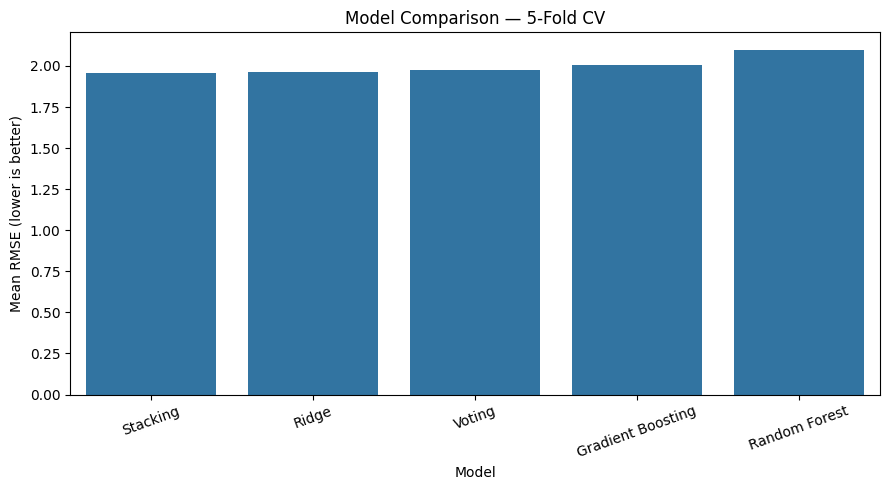

Selected model: Stacking
Held-out test R²: 0.538
Held-out test MAE: 1.5832
Held-out test RMSE: 2.0005


In [ ]:
results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=kf,
        scoring=scoring,
        n_jobs=1
    )

    results.append({
        "Model": name,
        "Mean R2": scores["test_R2"].mean(),
        "Std R2": scores["test_R2"].std(),
        "Mean MAE": -scores["test_MAE"].mean(),
        "Mean RMSE": -scores["test_RMSE"].mean()
    })

results_df = pd.DataFrame(results).sort_values("Mean RMSE")

display(results_df.round(4))

plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x="Model", y="Mean RMSE")
plt.title("Model Comparison — 5-Fold CV")
plt.ylabel("Mean RMSE (lower is better)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]

best_model.fit(X_train, y_train)
test_predictions = best_model.predict(X_test)

print("Selected model:", best_model_name)
print("Held-out test R²:", round(r2_score(y_test, test_predictions), 4))
print("Held-out test MAE:", round(mean_absolute_error(y_test, test_predictions), 4))
print(
    "Held-out test RMSE:",
    round(np.sqrt(mean_squared_error(y_test, test_predictions)), 4)
)

In [ ]:
# Preprocess input features using training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Use a limited sample for computational efficiency
rng = np.random.RandomState(42)
sample_size = min(2000, X_train_processed.shape[0])

sample_indices = rng.choice(
    X_train_processed.shape[0],
    size=sample_size,
    replace=False
)

X_anomaly = X_train_processed[sample_indices]

# Isolation Forest
iso_model = IsolationForest(
    contamination="auto",
    random_state=42
)
iso_labels = iso_model.fit_predict(X_anomaly)

# LOF
lof_model = LocalOutlierFactor(
    n_neighbors=min(20, sample_size - 1),
    contamination="auto"
)
lof_labels = lof_model.fit_predict(X_anomaly)

# One-Class SVM
svm_model = OneClassSVM(
    kernel="rbf",
    nu=0.05,
    gamma="scale"
)
svm_labels = svm_model.fit_predict(X_anomaly)

anomaly_results = pd.DataFrame({
    "Method": ["Isolation Forest", "LOF", "One-Class SVM"],
    "Records analyzed": [sample_size] * 3,
    "Anomalies detected": [
        np.sum(iso_labels == -1),
        np.sum(lof_labels == -1),
        np.sum(svm_labels == -1)
    ]
})

display(anomaly_results)

# Original records flagged by Isolation Forest

# Original records flagged by Isolation Forest
anomaly_train_positions = sample_indices[iso_labels == -1]

# Get original row indices from X_train
anomaly_indices = X_train.iloc[anomaly_train_positions].index

# Retrieve matching rows from df
anomaly_df = df.loc[df.index.intersection(anomaly_indices)].copy()

print("Anomalies found:", len(anomaly_df))
display(anomaly_df.head(10))


,Method,Records analyzed,Anomalies detected
0,Isolation Forest,2000,51
1,LOF,2000,0
2,One-Class SVM,2000,103


Anomalies found: 51


,Cell_stack_sequence,Cell_architecture,Substrate_stack_sequence,ETL_stack_sequence,ETL_deposition_procedure,Perovskite_composition_a_ions,Perovskite_composition_b_ions,Perovskite_composition_c_ions,Perovskite_composition_short_form,Perovskite_additives_compounds,...,Backcontact_stack_sequence,Backcontact_thickness_list,Backcontact_deposition_procedure,Encapsulation,Encapsulation_stack_sequence,JV_measured,JV_default_Voc,JV_default_Jsc,JV_default_FF,JV_default_PCE
328,SLG | FTO | TiO2-c | TiO2-mp | Perovskite | Ca...,nip,SLG | FTO,TiO2-c | TiO2-mp,Spin-coating | Spin-coating,FA; MA,Pb,Br; I,FAMAPbBrI,Cl,...,Carbon,NaN,Doctor blading,False,Unknown,True,1.030,21.12,NaN,14.61
659,SLG | ITO | C60 | BCP | Perovskite | NiO-c | Ag,pin,SLG | ITO,C60 | BCP,Evaporation | Evaporation,Cs,Pb,Br; I,CsPbBrI,Rb,...,Ag,100.0,Evaporation,False,Unknown,True,1.041,15.79,0.75,12.29
674,SLG | FTO | TiO2-c | TiO2-mp | Perovskite | Ca...,nip,SLG | FTO,TiO2-c | TiO2-mp,Spin-coating | Spin-coating,Cs; FA; MA,Pb,Br; I,CsFAMAPbBrI,Rb,...,Carbon,NaN,Doctor blading,False,Unknown,True,1.059,24.19,0.65,16.69
758,SLG | FTO | TiO2-c | TiO2-mp | Perovskite | Ca...,nip,SLG | FTO,TiO2-c | TiO2-mp,Spin-coating | Spin-coating,FA,Pb,I,FAPbI,SnF2,...,Carbon,NaN,Doctor blading,False,Unknown,True,0.976,22.37,0.68,14.84
1069,SLG | ITO | PCBM-60 | Perovskite | PEDOT:PSS | Al,pin,SLG | ITO,PCBM-60,Spin-coating,FA; MA,Pb,Br; I,FAMAPbBrI,SnF2,...,Al,100.0,Evaporation,True,Epoxy,True,1.052,21.45,0.71,16.08
1624,SLG | ITO | C60 | BCP | Perovskite | NiO-c | Ag,pin,SLG | ITO,C60 | BCP,Evaporation | Evaporation,FA; MA,Pb,Br; I,FAMAPbBrI,5-AVAI,...,Ag,100.0,Evaporation,True,UV-curable epoxy,True,1.206,18.27,0.70,15.36
2096,PEN | ITO | PCBM-60 | BCP | Perovskite | PEDOT...,pin,PEN | ITO,PCBM-60 | BCP,Spin-coating | Evaporation,FA; MA,Pb,Br; I,FAMAPbBrI,Undoped,...,Ag,100.0,Evaporation,True,SLG,True,1.147,22.31,0.71,18.13
2366,SLG | FTO | TiO2-c | TiO2-mp | Perovskite | Ca...,nip,SLG | FTO,TiO2-c | TiO2-mp,Spin-coating | Spin-coating,FA,Sn,I,FASnI,Pb(SCN)2,...,Carbon,NaN,Doctor blading,False,Unknown,True,0.592,18.53,0.68,7.47
2958,PEN | ITO | PCBM-60 | BCP | Perovskite | PEDOT...,pin,PEN | ITO,PCBM-60 | BCP,Spin-coating | Evaporation,Cs; FA; MA,Pb,Br; I,CsFAMAPbBrI,Pb(SCN)2,...,Ag,100.0,Evaporation,False,Unknown,True,1.100,18.74,0.70,14.40
3121,SLG | FTO | TiO2-c | TiO2-mp | Perovskite | Ca...,nip,SLG | FTO,TiO2-c | TiO2-mp,Spin-coating | Spin-coating,Cs,Pb,Br; I,CsPbBrI,SnF2,...,Carbon,NaN,Doctor blading,False,Unknown,True,0.935,16.43,0.63,9.67


,Feature,Importance
6,Perovskite_composition_b_ions,5.289571
5,Perovskite_composition_a_ions,0.691708
7,Perovskite_composition_c_ions,0.514493
8,Perovskite_composition_short_form,0.373062
15,Perovskite_deposition_quenching_induced_crysta...,0.263464
10,Perovskite_additives_concentrations,0.223503
18,HTL_stack_sequence,0.200994
4,ETL_deposition_procedure,0.133427
16,Perovskite_deposition_thermal_annealing_temper...,0.102702
21,Backcontact_thickness_list,0.055903


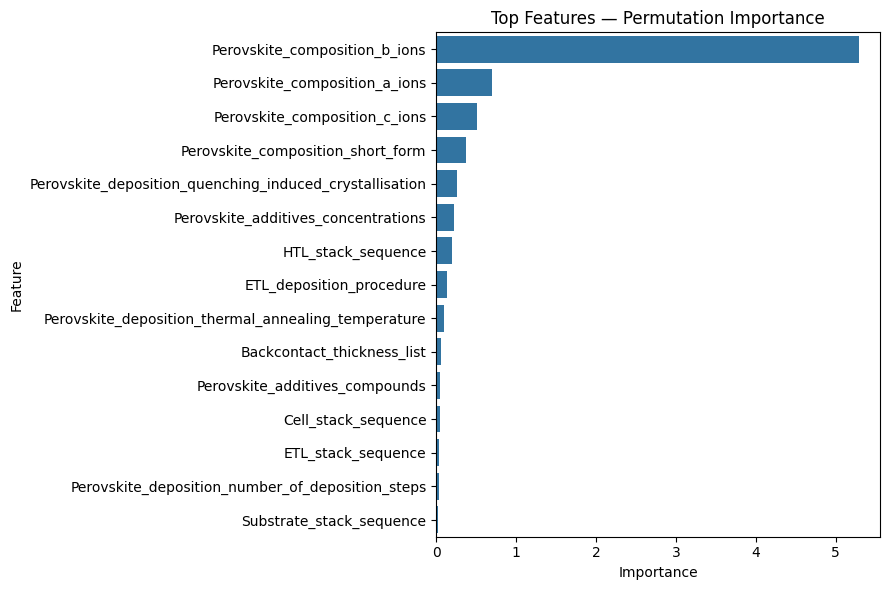

In [ ]:
importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="neg_mean_squared_error",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

plt.figure(figsize=(9, 6))
sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)
plt.title("Top Features — Permutation Importance")
plt.tight_layout()
plt.show()

In [ ]:
%pip -q install shap

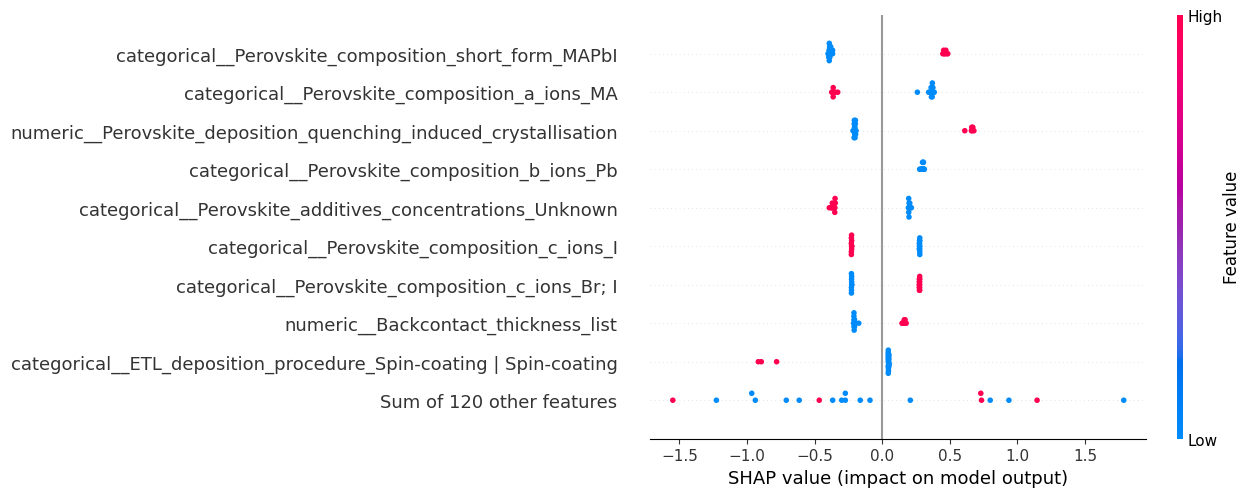

In [ ]:
import shap
import numpy as np
import pandas as pd

# Extract the preprocessor and the final model from the pipeline
preprocessor = best_model.named_steps['preprocessor']
regressor = best_model.named_steps['model']

# Select small samples from the original dataset
background_raw = X_train.sample(
    n=min(100, len(X_train)),
    random_state=42
)

explain_raw = X_test.sample(
    n=min(20, len(X_test)),
    random_state=42
)

# Transform raw features into numeric representations
background_processed = preprocessor.transform(background_raw)
explain_processed = preprocessor.transform(explain_raw)

# Handle sparse matrix output if necessary
if hasattr(background_processed, "toarray"):
    background_processed = background_processed.toarray()
if hasattr(explain_processed, "toarray"):
    explain_processed = explain_processed.toarray()

# Extract processed feature names for plotting
feature_names = preprocessor.get_feature_names_out()

# Explain the model predictions using processed numeric data
explainer = shap.Explainer(
    regressor.predict,
    background_processed,
    algorithm="permutation"
)

# Calculate SHAP values
shap_values = explainer(
    explain_processed,
    max_evals=2 * explain_processed.shape[1] + 1
)

# Assign proper feature names to the SHAP values object
shap_values.feature_names = list(feature_names)

# Display feature importance
shap.plots.beeswarm(shap_values)

Nominal coverage: 90%
Observed coverage: 88.62 %
Mean interval width: 6.4222


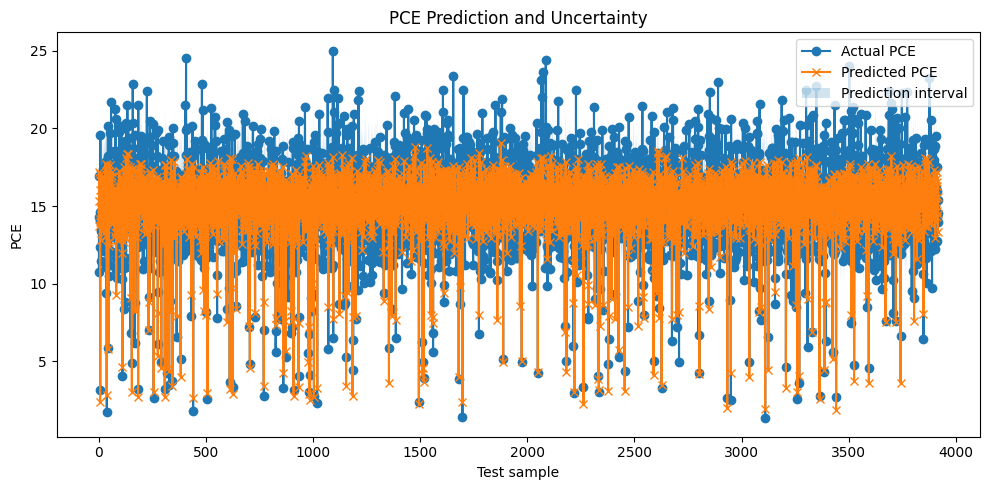

In [ ]:
lower_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(
        loss="quantile",
        alpha=0.05,
        n_estimators=100,
        random_state=42
    ))
])

upper_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(
        loss="quantile",
        alpha=0.95,
        n_estimators=100,
        random_state=42
    ))
])

lower_model.fit(X_train, y_train)
upper_model.fit(X_train, y_train)

lower_predictions = lower_model.predict(X_test)
upper_predictions = upper_model.predict(X_test)

interval_lower = np.minimum(lower_predictions, upper_predictions)
interval_upper = np.maximum(lower_predictions, upper_predictions)

covered = (
    (y_test.to_numpy() >= interval_lower) &
    (y_test.to_numpy() <= interval_upper)
)

coverage = covered.mean()
mean_width = np.mean(interval_upper - interval_lower)

print("Nominal coverage: 90%")
print("Observed coverage:", round(coverage * 100, 2), "%")
print("Mean interval width:", round(mean_width, 4))

plt.figure(figsize=(10, 5))
plt.plot(y_test.to_numpy(), label="Actual PCE", marker="o")
plt.plot(test_predictions, label="Predicted PCE", marker="x")
plt.fill_between(
    np.arange(len(y_test)),
    interval_lower,
    interval_upper,
    alpha=0.2,
    label="Prediction interval"
)
plt.title("PCE Prediction and Uncertainty")
plt.xlabel("Test sample")
plt.ylabel("PCE")
plt.legend()
plt.tight_layout()
plt.show()

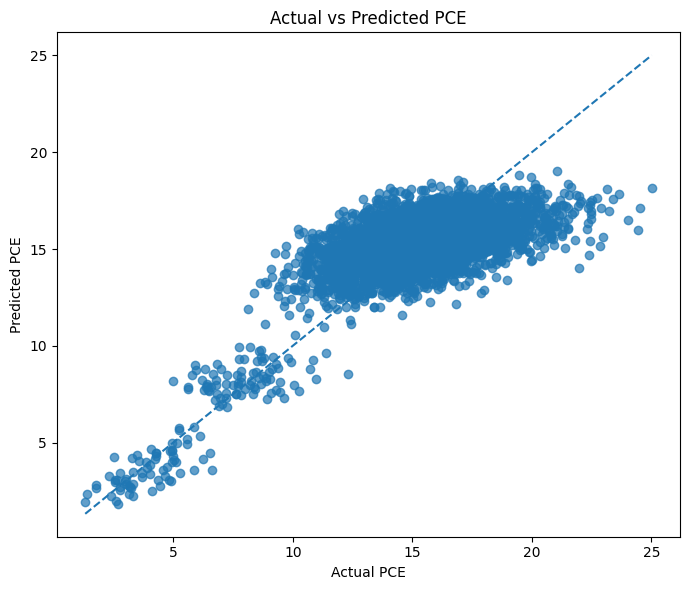

,Best Model,Test R2,Test MAE,Test RMSE,Interval Coverage (%),Mean Interval Width
0,Stacking,0.538,1.5832,2.0005,88.6166,6.4222


Three CSV result files created.


In [ ]:
# Actual versus predicted PCE
plt.figure(figsize=(7, 6))
plt.scatter(y_test, test_predictions, alpha=0.7)

low = min(y_test.min(), test_predictions.min())
high = max(y_test.max(), test_predictions.max())

plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual PCE")
plt.ylabel("Predicted PCE")
plt.title("Actual vs Predicted PCE")
plt.tight_layout()
plt.show()

# Final metrics
final_metrics = pd.DataFrame([{
    "Best Model": best_model_name,
    "Test R2": r2_score(y_test, test_predictions),
    "Test MAE": mean_absolute_error(y_test, test_predictions),
    "Test RMSE": np.sqrt(mean_squared_error(y_test, test_predictions)),
    "Interval Coverage (%)": coverage * 100,
    "Mean Interval Width": mean_width
}])

display(final_metrics.round(4))

# Export predictions and model comparison
predictions_df = pd.DataFrame({
    "Actual_PCE": y_test.to_numpy(),
    "Predicted_PCE": test_predictions,
    "Lower_90_Interval": interval_lower,
    "Upper_90_Interval": interval_upper
})

predictions_df.to_csv("solar_cell_predictions.csv", index=False)
results_df.to_csv("solar_cell_model_comparison.csv", index=False)
importance_df.to_csv("solar_cell_feature_importance.csv", index=False)

print("Three CSV result files created.")

In [ ]:
files.download("solar_cell_predictions.csv")
files.download("solar_cell_model_comparison.csv")
files.download("solar_cell_feature_importance.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Define models
models = {
    "Ridge Regression": ridge_model,
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model,
    "Voting Regressor": voting_model,
    "Stacking Regressor": stacking_model
}

results = []

# Safely fit and obtain predictions for all models
for name, model in models.items():
    print(f"Fitting and evaluating {name}...")
    model.fit(X_train, y_train)
    predictions = np.asarray(model.predict(X_test)).reshape(-1)
    actual = np.asarray(y_test).reshape(-1)

    mae = mean_absolute_error(actual, predictions)
    rmse = np.sqrt(mean_squared_error(actual, predictions))
    r2 = r2_score(actual, predictions)

    actual_mean = np.mean(actual)
    pred_mean = np.mean(predictions)
    diff = pred_mean - actual_mean

    results.append({
        "Model": name,
        "Actual Mean PCE (%)": actual_mean,
        "Predicted Mean PCE (%)": pred_mean,
        "PCE Deviation (pp)": diff,
        "R2 Score": r2,
        "MAE": mae,
        "RMSE": rmse
    })

results_df = pd.DataFrame(results)

# Calculate relative improvements compared to Ridge Regression as baseline
baseline_r2 = results_df.loc[results_df["Model"] == "Ridge Regression", "R2 Score"].values[0]
baseline_mae = results_df.loc[results_df["Model"] == "Ridge Regression", "MAE"].values[0]
baseline_rmse = results_df.loc[results_df["Model"] == "Ridge Regression", "RMSE"].values[0]

results_df["R2 Improvement (pp)"] = results_df["R2 Score"] - baseline_r2
results_df["MAE Reduction (%)"] = ((baseline_mae - results_df["MAE"]) / baseline_mae) * 100
results_df["RMSE Reduction (%)"] = ((baseline_rmse - results_df["RMSE"]) / baseline_rmse) * 100

print("\n=== DETAILED SOLAR CELL EFFICIENCY MODEL COMPARISON ===")
display(results_df.round(4))

# Find the best model based on R2
best_model = results_df.loc[results_df["R2 Score"].idxmax()]
best_name = best_model["Model"]

print(f"\n=== SUMMARY OF EFFICIENCY IMPROVEMENTS ===")
print(f"Best Performing Model: {best_name}")
print(f"- R² Score: {best_model['R2 Score']:.4f} (an increase of {best_model['R2 Improvement (pp)'] * 100:.2f} percentage points over baseline Ridge)")
print(f"- Mean Predicted PCE: {best_model['Predicted Mean PCE (%)']:.2f}% (Actual Mean: {best_model['Actual Mean PCE (%)']:.2f}%)")
print(f"- MAE: {best_model['MAE']:.4f} ({best_model['MAE Reduction (%)']:.2f}% reduction in absolute error)")
print(f"- RMSE: {best_model['RMSE']:.4f} ({best_model['RMSE Reduction (%)']:.2f}% reduction in standard error)")

Fitting and evaluating Ridge Regression...
Fitting and evaluating Random Forest...
Fitting and evaluating Gradient Boosting...
Fitting and evaluating Voting Regressor...
Fitting and evaluating Stacking Regressor...

=== SOLAR CELL EFFICIENCY: MODEL COMPARISON ===


,Model,Actual Mean PCE (%),Predicted Mean PCE (%),Difference (percentage points),R2 Score,MAE,RMSE
0,Ridge Regression,15.0105,15.0016,-0.0089,0.5379,1.5846,2.0007
1,Random Forest,15.0105,15.0228,0.0124,0.4522,1.7258,2.1782
2,Gradient Boosting,15.0105,15.0029,-0.0076,0.5196,1.6109,2.0399
3,Voting Regressor,15.0105,15.0099,-0.0006,0.5255,1.6021,2.0273
4,Stacking Regressor,15.0105,15.0032,-0.0073,0.5380,1.5832,2.0005



Best performing model: Stacking Regressor
Best R² Score: 0.5380
Mean Predicted PCE: 15.00%
Difference from Actual Mean PCE: -0.0073 percentage points
